# Chapitre 3 - Exercices 3.11 et 3.12

Ces deux exercices portent sur les modèles présentés au cours 6 :

- **3.11** : event sourcing, fréquence optimale des instantanés et ordre des
  événements entre partitions (calcul et simulation) ;
- **3.12** : DataFrames, matrices creuses et schéma en étoile : dimensionner la
  mémoire et le calcul (calcul et mesure).

In [1]:
import copy
import math
import time
import zlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels_ed2 as e2
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 3.11 : instantanés et ordre des événements

**Énoncé.** Un service en event sourcing reçoit $\lambda$ = 200 événements par seconde.
Rejouer un événement dans la projection principale coûte $c$ = 20 µs ; prendre un
instantané (sérialiser la vue) coûte $S$ = 2 s. Le service redémarre en moyenne $r$ = une
fois par jour (déploiement, panne).

1. Sans instantané, combien de temps dure la reconstruction après 30 jours de
   fonctionnement ?
2. On prend un instantané tous les $k$ événements ; un redémarrage charge le dernier
   instantané puis rejoue en moyenne $k/2$ événements. Écrire le coût quotidien total
   $C(k)$ (instantanés + reconstructions) et trouver le $k^*$ optimal. Que vaut alors le
   temps moyen de reconstruction ?
3. Vérifier sur les projections du cours 6 qu'une reconstruction depuis un instantané
   donne exactement la même vue qu'un rejeu complet.
4. Pour monter en charge, on répartit les événements entre 4 partitions consommées en
   parallèle. Comparer un partitionnement **tourniquet** (événement $i$ dans la partition
   $i \bmod 4$) et un partitionnement **par réservation** (hachage de l'identifiant).

**Rappels.** Les vues se reconstruisent par rejeu dans l'ordre du journal ; le rejeu
coûte la longueur du journal ; l'ordre doit être respecté (cours 6, sections 3 et 4,
section *Event Sourcing and CQRS*).

**Solution.**

*1.* $30 \times 86\,400 \times 200 = 5{,}18 \cdot 10^8$ événements, à 20 µs : environ
$10\,400$ s, soit **2 h 53** d'indisponibilité de la vue à chaque redémarrage.

*2.* Événements par jour : $E = 200 \times 86\,400 = 1{,}728 \cdot 10^7$. Instantanés :
$E/k$ par jour, coût $ES/k$. Reconstructions : $r$ par jour, coût $r\,c\,k/2$. Donc
$$C(k) = \frac{E S}{k} + \frac{r c k}{2}, \qquad C'(k) = 0 \iff k^* = \sqrt{\frac{2 E S}{r c}}.$$
Numériquement $k^* = \sqrt{2 \times 1{,}728 \cdot 10^7 \times 2 / (20 \cdot 10^{-6})}
\approx 1{,}86 \cdot 10^6$ événements (un instantané toutes les 2 h 35). À l'optimum les
deux termes sont égaux : $\approx 18{,}6$ s d'instantanés par jour, et une reconstruction
moyenne de $k^* c / 2 \approx$ **18,6 s** au lieu de presque trois heures.

*3.* Voir le code : on sérialise la vue (copie profonde) tous les $k$ événements.

*4.* En tourniquet, l'annulation d'une réservation peut tomber dans une autre partition
que la réservation elle-même, et être consommée **avant** : la projection reçoit une
annulation d'une réservation inconnue. En partitionnant par identifiant de réservation,
tous les événements d'une même réservation sont dans la même partition, dans l'ordre :
l'ordre **par réservation** est garanti, même si l'ordre global ne l'est plus.

1. sans instantané : 10368 s = 2.88 h
2. k* = 1.86e+06 événements (toutes les 2.58 h) ; reconstruction moyenne 18.6 s


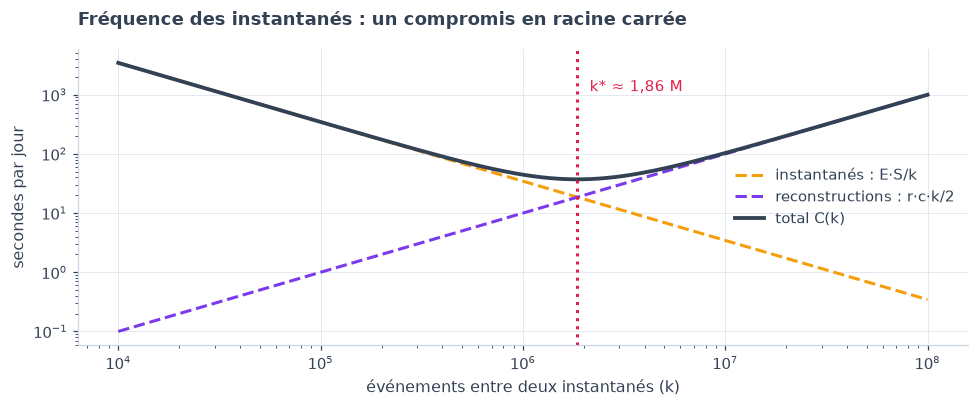

In [2]:
E, S, r, c = 200 * 86_400, 2.0, 1.0, 20e-6
k_star = math.sqrt(2 * E * S / (r * c))
print(f"1. sans instantané : {30 * E * c:.0f} s = {30 * E * c / 3600:.2f} h")
print(f"2. k* = {k_star:.3g} événements (toutes les {k_star / 200 / 3600:.2f} h) ; reconstruction moyenne {k_star * c / 2:.1f} s")
ks = np.logspace(4, 8, 200)
C = E * S / ks + r * c * ks / 2
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.loglog(ks, E * S / ks, color=AMBER, ls="--", label="instantanés : E·S/k")
ax.loglog(ks, r * c * ks / 2, color=VIOLET, ls="--", label="reconstructions : r·c·k/2")
ax.loglog(ks, C, color=SLATE, lw=2.5, label="total C(k)")
ax.axvline(k_star, color=ROSE, ls=":"); ax.text(k_star * 1.15, C.max() / 3, f"k* ≈ {k_star / 1e6:.2f} M".replace(".", ","), color=ROSE)
ax.set_xlabel("événements entre deux instantanés (k)"); ax.set_ylabel("secondes par jour")
ax.set_title("Fréquence des instantanés : un compromis en racine carrée")
ax.legend(); plt.tight_layout(); plt.show()

**Vérification 3** : reconstruction depuis un instantané sur le journal de la conférence.

In [3]:
svc = e2.ConferenceService()
for ts, cmd in e2.make_conference_commands(5000, capacity=6000, seed=3):
    svc.handle(cmd, ts)
events = svc.log.events
k = 700
snapshots = {}
vue = e2.BookingStatus()
for ev in events:
    vue.apply(ev)
    if (ev.seq + 1) % k == 0:
        snapshots[ev.seq] = copy.deepcopy(vue)          # instantané : la vue après l'événement seq
complet = e2.replay(events, e2.BookingStatus())
dernier = max(snapshots)
depuis_snap = e2.replay(events[dernier + 1:], copy.deepcopy(snapshots[dernier]))
assert depuis_snap.status == complet.status
print(f"{len(events)} événements ; reconstruction depuis l'instantané n° {dernier} : "
      f"{len(events) - dernier - 1} événements rejoués au lieu de {len(events)} ; vue identique")

4577 événements ; reconstruction depuis l'instantané n° 4199 : 377 événements rejoués au lieu de 4577 ; vue identique


**Vérification 4** : 200 consommations simulées de 4 partitions, chacune lue dans l'ordre
mais entrelacée au hasard avec les autres.

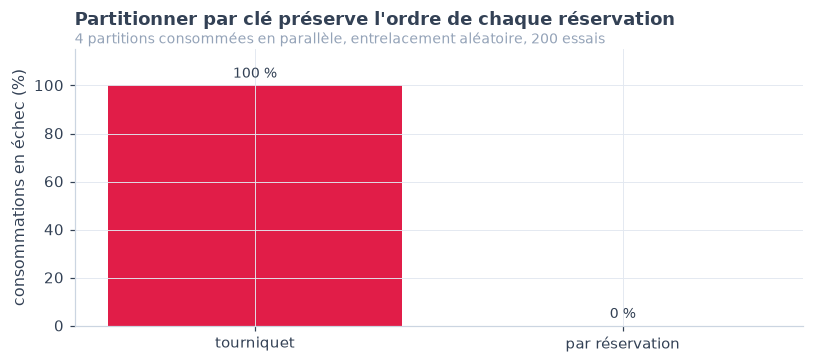

In [4]:
def consume(partitions, seed):
    """Entrelace aléatoirement des partitions (chacune dans son ordre) et applique la projection."""
    r_ = np.random.default_rng(seed)
    idx = [0] * len(partitions)
    vue = e2.BookingStatus()
    while any(i < len(p) for i, p in zip(idx, partitions)):
        choix = [j for j, p in enumerate(partitions) if idx[j] < len(p)]
        j = choix[int(r_.integers(len(choix)))]
        try:
            vue.apply(partitions[j][idx[j]])
        except KeyError:
            return False
        idx[j] += 1
    return True

bookings = [ev for ev in events if ev.type in ("SeatsBooked", "BookingCancelled")]
tourniquet = [bookings[i::4] for i in range(4)]
par_cle = [[ev for ev in bookings if zlib.crc32(ev.data["booking"].encode()) % 4 == j] for j in range(4)]
ok_t = np.mean([consume(tourniquet, s) for s in range(200)])
ok_c = np.mean([consume(par_cle, s) for s in range(200)])
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(["tourniquet", "par réservation"], [100 * (1 - ok_t), 100 * (1 - ok_c)], color=[ROSE, TEAL])
annotate_bars(ax, "{:.0f} %")
ax.set_ylim(0, 115); ax.set_ylabel("consommations en échec (%)")
ax.set_title("Partitionner par clé préserve l'ordre de chaque réservation")
subtitle(ax, "4 partitions consommées en parallèle, entrelacement aléatoire, 200 essais")
plt.tight_layout(); plt.show()

En tourniquet, toutes les consommations échouent : il suffit qu'une seule
annulation passe devant sa réservation. Partitionner par clé ne garantit plus l'ordre
**global**, mais garantit l'ordre de chaque réservation, ce qui suffit à cette
projection. (Une projection globale, comme le nombre de places disponibles, aurait
besoin de l'ordre total : nous y reviendrons au chapitre 10.)

> **À retenir.** Instantanés tous les $k^* = \sqrt{2ES/(rc)}$ événements : coût
> d'instantanés et coût de reconstruction s'équilibrent. Pour paralléliser, partitionner
> le journal **par clé** préserve l'ordre par entité, pas l'ordre global.

## Exercice 3.12 : DataFrames, matrices creuses et schéma en étoile

**Énoncé.**

1. Une plateforme a 2 millions d'utilisateurs, 100 000 articles et 50 notes par
   utilisateur en moyenne. Quelle mémoire faut-il pour la matrice utilisateurs × articles
   en dense (float32), en COO (ligne, colonne, valeur : 3 × 4 octets par note) et en CSR ?
2. Combien de multiplications-additions coûte un produit matrice × vecteur dans chaque
   format ?
3. On encode en one-hot une colonne « ville » à 10 000 valeurs sur 1 million de lignes.
   Quelle taille en dense (1 octet par case) et en creux ?
4. Une table de faits d'un milliard de ventes a 5 clés étrangères (4 octets) et 3 mesures
   (8 octets). Une version OBT y recopie les colonnes des dimensions, environ 100 octets
   par ligne. Quel facteur d'espace ?
5. Vérifier les formules de 1 et 2 par la mesure sur une instance réduite.

**Rappels.** Pivot d'une table de notes en matrice creuse, format CSR, encodage one-hot
(cours 6, section *DataFrames, Matrices, and Arrays*) ; schémas en étoile et OBT (cours 2,
section *Stars and Snowflakes: Schemas for Analytics*).

**Solution.**

*1.* Dense : $2 \cdot 10^6 \times 10^5 \times 4 = 8 \cdot 10^{11}$ octets = **800 Go**.
Non nuls : $nnz = 10^8$. COO : $12 \times 10^8$ = 1,2 Go. CSR : valeurs et colonnes
$8 \times 10^8$ = 800 Mo, plus le tableau `indptr` de $(2 \cdot 10^6 + 1) \times 8$ octets
= 16 Mo : **816 Mo**, mille fois moins que le dense.

*2.* Dense : $2 \cdot 10^{11}$ opérations ; creux : $nnz = 10^8$, soit **2 000 fois
moins**.

*3.* Dense : $10^6 \times 10^4 = 10^{10}$ cases = 10 Go ; creux : un seul 1 par ligne,
$10^6$ valeurs non nulles (quelques Mo).

*4.* Étoile : $5 \times 4 + 3 \times 8 = 44$ octets par ligne, soit 44 Go (plus des
dimensions négligeables). OBT : $44 + 100 = 144$ octets, soit 144 Go, **3,3 fois** plus
(avant compression : en stockage par colonnes, les colonnes recopiées, très répétitives,
se compressent extrêmement bien, chapitre 4).

In [5]:
print(f"1. dense {2e6 * 1e5 * 4 / 1e9:.0f} Go ; COO {12 * 1e8 / 1e9:.1f} Go ; CSR {(8e8 + 8 * (2e6 + 1)) / 1e6:.0f} Mo")
print(f"2. dense {2e6 * 1e5:.0e} opérations ; creux {1e8:.0e} ; rapport {2e6 * 1e5 / 1e8:.0f}")
print(f"3. one-hot dense {1e6 * 1e4 / 1e9:.0f} Go ; creux {1e6:.0e} valeurs non nulles")
print(f"4. étoile {1e9 * 44 / 1e9:.0f} Go ; OBT {1e9 * 144 / 1e9:.0f} Go ; facteur {144 / 44:.2f}")

1. dense 800 Go ; COO 1.2 Go ; CSR 816 Mo
2. dense 2e+11 opérations ; creux 1e+08 ; rapport 2000
3. one-hot dense 10 Go ; creux 1e+06 valeurs non nulles
4. étoile 44 Go ; OBT 144 Go ; facteur 3.27


**Vérification 5** sur une instance réduite : 10 000 utilisateurs, 2 000 articles,
environ 50 notes par utilisateur. On mesure la taille CSR et le temps du produit matrice
× vecteur, en dense (NumPy) et en creux (notre `csr_matvec`).

,format,octets (formule),octets (mesure),opérations,ms par produit
0,dense,80000000,80000000,20000000,5.257
1,CSR,4081952,4081952,500243,0.843


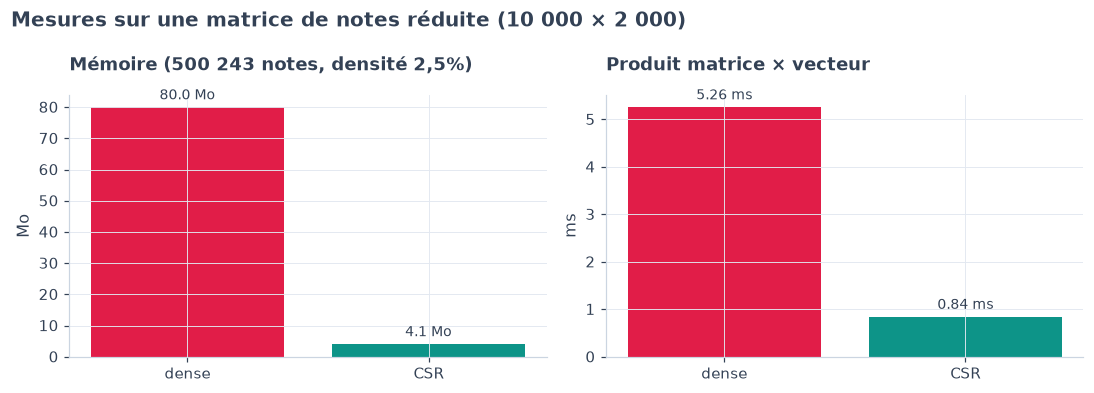

In [6]:
df = e2.make_ratings(10_000, 2_000, per_user=50, seed=1)
nnz = len(df)
csr = e2.to_csr(df.user_id, df.movie_id, df.rating, (10_000, 2_000))
dense = np.zeros((10_000, 2_000), dtype=np.float32)
dense[df.user_id, df.movie_id] = df.rating
x = rng.random(2_000).astype(np.float32)
assert np.allclose(e2.csr_matvec(csr, x), dense @ x, rtol=1e-4)

def best(f, n=7):
    t = np.inf
    for _ in range(n):
        t0 = time.perf_counter(); f(); t = min(t, time.perf_counter() - t0)
    return t * 1e3

t_dense, t_csr = best(lambda: dense @ x), best(lambda: e2.csr_matvec(csr, x))
mesures = pd.DataFrame({
    "format": ["dense", "CSR"],
    "octets (formule)": [10_000 * 2_000 * 4, nnz * 8 + 10_001 * 8],
    "octets (mesure)": [dense.nbytes, e2.csr_nbytes(csr)],
    "opérations": [10_000 * 2_000, nnz],
    "ms par produit": [t_dense, t_csr],
})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(mesures["format"], mesures["octets (mesure)"] / 1e6, color=[ROSE, TEAL]); annotate_bars(axes[0], "{:.1f} Mo")
axes[0].set_ylabel("Mo"); axes[0].set_title(f"Mémoire ({fmt(nnz)} notes, densité {nnz / 2e7:.1%})".replace(".", ","))
axes[1].bar(mesures["format"], mesures["ms par produit"], color=[ROSE, TEAL]); annotate_bars(axes[1], "{:.2f} ms")
axes[1].set_ylabel("ms"); axes[1].set_title("Produit matrice × vecteur")
finish(fig, "Mesures sur une matrice de notes réduite (10 000 × 2 000)")
mesures

Les tailles mesurées coïncident avec les formules. En temps, le gain du format creux est
bien plus faible que le rapport des opérations : le produit dense de NumPy est une boucle
vectorisée très optimisée (accès mémoire contigus, instructions SIMD), alors que le
format creux fait des accès indirects (`x[indices]`) ; à faible densité et grande taille,
le creux finit toujours par gagner, et surtout il **tient en mémoire** quand le dense ne
tient plus.

> **À retenir.** Mémoire d'une matrice creuse : $\approx 8\,nnz$ octets en CSR contre
> $4\,mn$ en dense ; calcul en $O(nnz)$ contre $O(mn)$. L'encodage one-hot et les
> matrices de notes sont extrêmement creux. Une OBT multiplie l'espace brut par le
> rapport (faits + dimensions) / faits.